## Câu 3: Phân tích doanh thu theo quốc gia và nhóm hàng, xác định Top 10 nhóm hàng, xây dựng bảng xếp hạng, biểu đồ và nhận xét
### Yêu cầu
- Phân tích doanh thu theo quốc gia.
- Phân tích doanh thu theo nhóm hàng.
- Xác định Top 10 nhóm hàng.
- Xây dựng bảng xếp hạng và biểu đồ.
- Viết nhận xét dựa trên kết quả.

### Dữ liệu cần dùng
- `orders_cleaned.csv` có `category`, `total_amount_usd`, `order_status`, `customer_id`.
- `customers_cleaned.csv` có `country`.
- Hai bảng nối với nhau qua `customer_id`. Báo cáo chất lượng cho thấy khóa này khớp 100%.

### Hướng làm
1. Đọc dữ liệu → 2. Lọc đơn Delivered và gắn quốc gia → 3. Xếp hạng quốc gia → 4. Xếp hạng nhóm hàng và Top 10 → 5. Heatmap kết hợp → 6. Kết luận.

### 1. Import thư viện và đọc dữ liệu
**Mục tiêu:** nạp 2 bảng cần dùng (`orders`, `customers`).
- `pandas`: xử lý bảng; `matplotlib`: vẽ biểu đồ; `Path`: xử lý đường dẫn.
- **Kết quả đúng:** `(25000, 29) (8000, 20)`. Nếu khác nghĩa là đọc sai file.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# NOTE: file sạch nằm trong data/cleaned; notebook nằm trong notebooks/ nên dùng ../data/cleaned
DATA_DIR = Path('../data/cleaned')

orders = pd.read_csv(DATA_DIR / 'orders_cleaned.csv')
customers = pd.read_csv(DATA_DIR / 'customers_cleaned.csv')
print(orders.shape, customers.shape)
REPORT_DIR = Path('../exports/archive_static_png')
REPORT_DIR.mkdir(parents=True, exist_ok=True)

(25000, 29) (8000, 20)


### 2. Chuẩn bị dữ liệu: lọc đơn Delivered và gắn quốc gia
**Vấn đề:** bảng `orders` không có cột `country`, cột này nằm ở bảng `customers`, nên phải **merge** theo `customer_id`.
- Bước 1: lọc `order_status == 'Delivered'` để tính doanh thu thực.
- Bước 2: `merge(..., how='left')` giữ nguyên toàn bộ đơn hàng, chỉ thêm cột `country`.
- Bước 3: tính `TOTAL` (tổng doanh thu) để dùng làm mẫu số cho phần trăm ở các bước sau.

**Kiểm tra bắt buộc sau merge** (nếu sai thì mọi kết quả phía sau đều sai):
| Chỉ số | Giá trị đúng |
|---|---|
| Số đơn Delivered | 20.497 |
| Đơn thiếu quốc gia | 0 |
| Tổng doanh thu | $2,585,126.50 (khớp `monthly_revenue`) |

In [2]:
# NOTE: chỉ chọn 2 cột ['customer_id', 'country'] để tránh kéo thêm cột thừa từ customers
# NOTE: how='left' -> giữ nguyên số dòng của orders; nếu customers bị trùng customer_id thì số dòng sẽ tăng (sai)
df = orders[orders['order_status'] == 'Delivered'].merge(
    customers[['customer_id', 'country']], on='customer_id', how='left')

# NOTE: TOTAL là mẫu số để tính % thị phần ở các bước sau
TOTAL = df['total_amount_usd'].sum()
print('Số đơn:', len(df), '| Thiếu quốc gia:', df['country'].isna().sum(), '| Doanh thu:', round(TOTAL, 2))

Số đơn: 20497 | Thiếu quốc gia: 0 | Doanh thu: 2585126.5


### 3. Doanh thu theo quốc gia
#### 3.1 Bảng xếp hạng
**Mục tiêu:** xếp hạng 20 quốc gia theo doanh thu.
- `revenue`: tổng doanh thu; `orders`: số đơn; `aov`: giá trị trung bình mỗi đơn (Average Order Value).
- `share_%`: tỷ trọng so với tổng; `cum_%`: tỷ trọng **tích lũy**, dùng để xem mức độ tập trung (quy tắc Pareto 80/20).
- Chỉ nhìn doanh thu thì dễ kết luận sai; thêm `orders` và `aov` để biết quốc gia cao là do **nhiều đơn** hay do **đơn giá trị lớn**.

In [3]:
by_country = df.groupby('country').agg(
    revenue=('total_amount_usd', 'sum'),
    orders=('order_id', 'count'),
    aov=('total_amount_usd', 'mean')
).sort_values('revenue', ascending=False)   # NOTE: sắp giảm dần TRƯỚC khi tính cumsum, nếu không cum_% sẽ sai

by_country['share_%'] = by_country['revenue'] / TOTAL * 100
by_country['cum_%'] = by_country['share_%'].cumsum()      # NOTE: cộng dồn theo thứ tự đã xếp hạng
by_country.insert(0, 'rank', range(1, len(by_country) + 1))
by_country.round(2)

,rank,revenue,orders,aov,share_%,cum_%
country,,,,,,
United States,1,804770.60,6417,125.41,31.13,31.13
United Kingdom,2,268206.58,2139,125.39,10.37,41.51
India,3,236160.74,1858,127.10,9.14,50.64
Germany,4,201376.01,1544,130.42,7.79,58.43
France,5,156084.88,1267,123.19,6.04,64.47
Canada,6,137329.86,1076,127.63,5.31,69.78
Brazil,7,113563.05,931,121.98,4.39,74.17
Australia,8,103235.72,803,128.56,3.99,78.17
Mexico,9,93530.44,739,126.56,3.62,81.79


#### 3.2 Biểu đồ Top 10 quốc gia
**Mục tiêu:** so sánh trực quan quy mô doanh thu giữa 10 quốc gia đứng đầu.
- Dùng biểu đồ **cột ngang** vì tên quốc gia dài, dễ đọc hơn cột đứng.
- Sắp xếp **tăng dần** trước khi vẽ để nước lớn nhất nằm **trên cùng** (`barh` vẽ từ dưới lên).

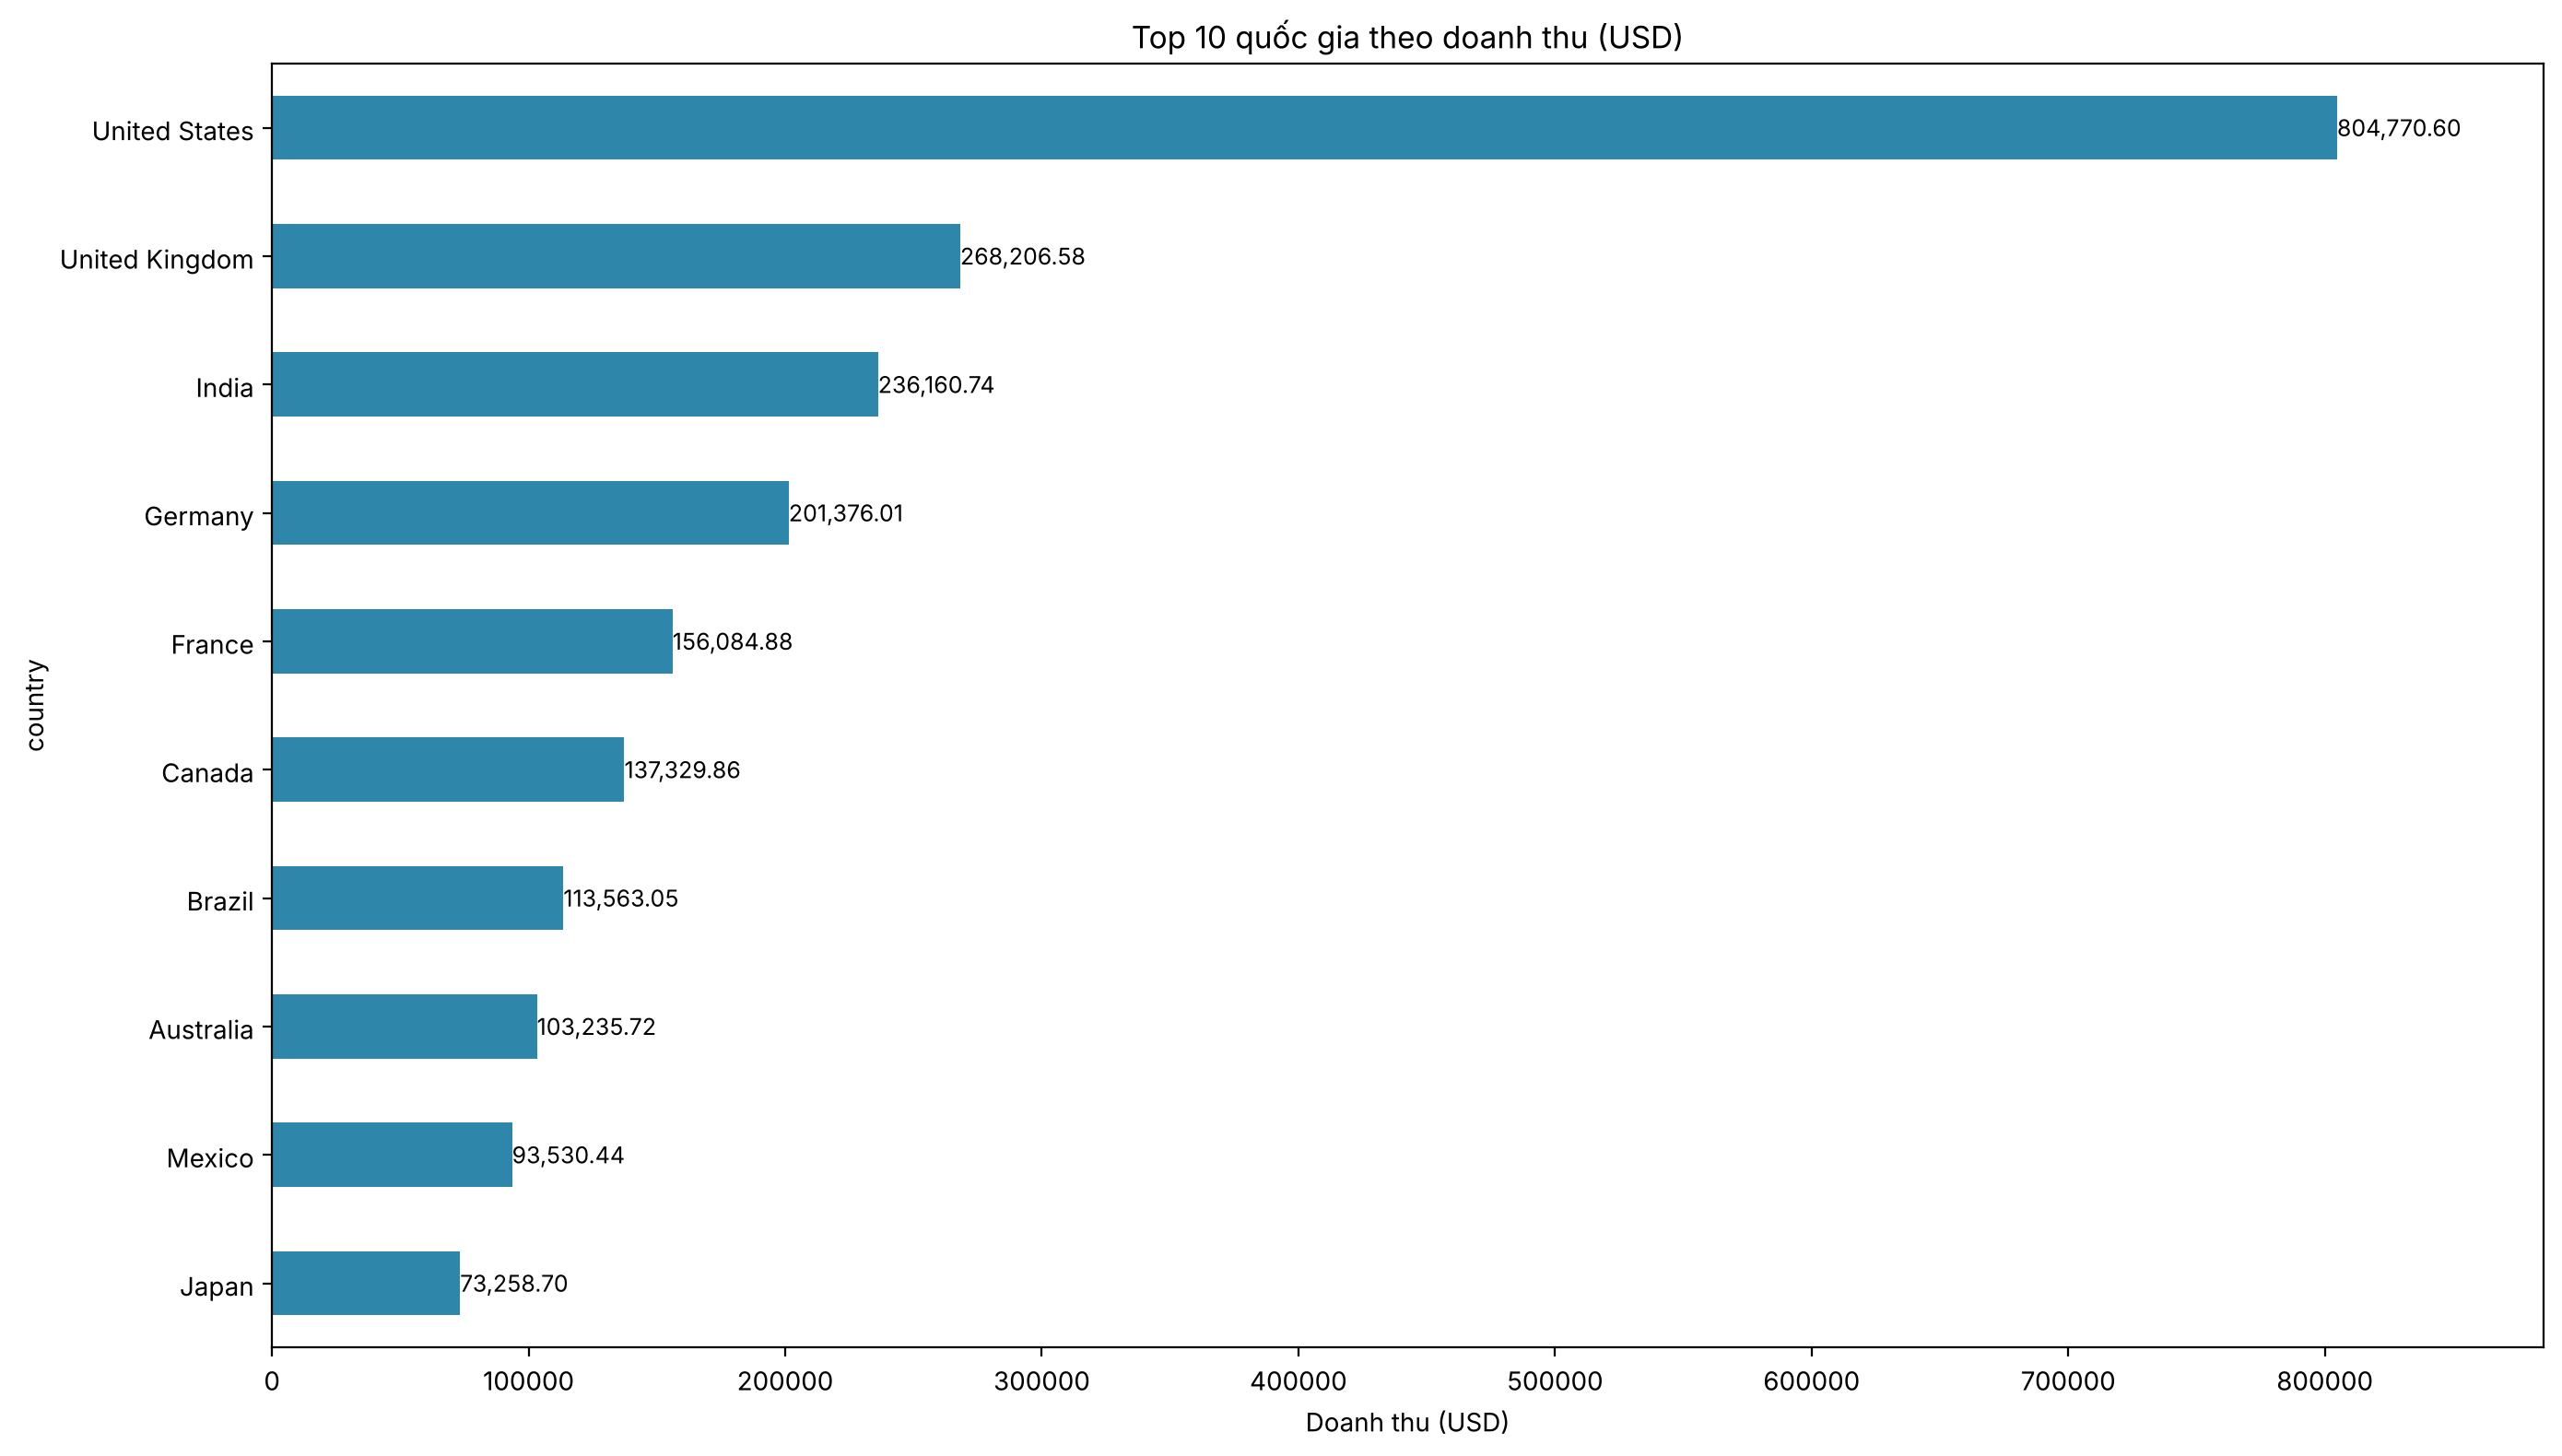

In [4]:
top10_country = by_country.head(10)

# NOTE: sắp tăng dần để nước lớn nhất nằm trên cùng biểu đồ
s = top10_country['revenue'].sort_values()

ax = s.plot.barh(figsize=(14, 8), color='#2E86AB')
ax.set_title('Top 10 quốc gia theo doanh thu (USD)')
ax.set_xlabel('Doanh thu (USD)')

# NOTE: nhãn phải lặp trên CHÍNH chuỗi s (đã sắp tăng dần). Lặp trên top10_country (giảm dần) sẽ gắn nhãn lệch hàng.
for i, value in enumerate(s):
    ax.text(value, i, f'{value:,.2f}', va='center', ha='left', fontsize=9)

ax.set_xlim(0, s.max() * 1.1)   # NOTE: chừa chỗ bên phải để nhãn không bị cắt
plt.tight_layout()
plt.savefig('../exports/archive_static_png/top10_country.png', dpi=150, bbox_inches='tight')
plt.show()

#### 3.3 Nhận xét về quốc gia
- **Doanh thu tập trung cao:** Mỹ đứng đầu với **$804,8K (31,1%)**, gấp ~3 lần Anh (10,4%). 5 nước đầu (Mỹ, Anh, Ấn Độ, Đức, Pháp) chiếm **64,5%**; 9 nước đầu vượt 80%.
- **AOV giữa các nước khá đều** (~$114–146) → chênh lệch doanh thu chủ yếu do **số lượng khách và số đơn**, không phải do giá trị mỗi đơn. Thị phần doanh thu của Mỹ (31,1%) gần trùng thị phần khách hàng (31,4%).
- Một số thị trường nhỏ (Thụy Điển, Ba Lan, UAE) có AOV cao ($134–146) nhưng quy mô thấp (1,3–1,7%), là tiềm năng nếu mở rộng tệp khách.

### 4. Doanh thu theo nhóm hàng và Top 10
#### 4.1 Bảng xếp hạng nhóm hàng
**Mục tiêu:** xếp hạng 14 nhóm hàng (`category`) và xác định **Top 10**.
- Cấu trúc giống bảng quốc gia để dễ so sánh và dễ nhớ.
- Dòng `print` cho biết Top 10 chiếm bao nhiêu % tổng doanh thu (kỳ vọng: **92,0%**).

In [5]:
by_cat = df.groupby('category').agg(
    revenue=('total_amount_usd', 'sum'),
    orders=('order_id', 'count'),
    aov=('total_amount_usd', 'mean')
).sort_values('revenue', ascending=False)   # NOTE: sắp giảm dần trước khi cumsum / head(10)

by_cat['share_%'] = by_cat['revenue'] / TOTAL * 100
by_cat['cum_%'] = by_cat['share_%'].cumsum()
by_cat.insert(0, 'rank', range(1, len(by_cat) + 1))

# NOTE: Top 10 = 10 dòng đầu của bảng đã sắp giảm dần theo doanh thu
top10_cat = by_cat.head(10)
print('Top 10 nhóm hàng chiếm', round(top10_cat['share_%'].sum(), 1), '% doanh thu')
top10_cat.round(2)

Top 10 nhóm hàng chiếm 92.0 % doanh thu


,rank,revenue,orders,aov,share_%,cum_%
category,,,,,,
Electronics,1,949184.30,3716,255.43,36.72,36.72
Clothing & Apparel,2,375528.98,3290,114.14,14.53,51.24
Home & Kitchen,3,354657.99,2480,143.01,13.72,64.96
Sports & Outdoors,4,133145.44,1460,91.20,5.15,70.11
Jewelry & Accessories,5,121346.55,796,152.45,4.69,74.81
Office Supplies,6,107213.66,633,169.37,4.15,78.95
Toys & Games,7,94991.49,1252,75.87,3.67,82.63
Beauty & Personal Care,8,83214.79,1401,59.40,3.22,85.85
Books,9,79412.54,1618,49.08,3.07,88.92


#### 4.2 Biểu đồ Top 10 nhóm hàng
**Mục tiêu:** minh họa Top 10 nhóm hàng đã xác định ở trên, cùng cách vẽ như biểu đồ quốc gia.

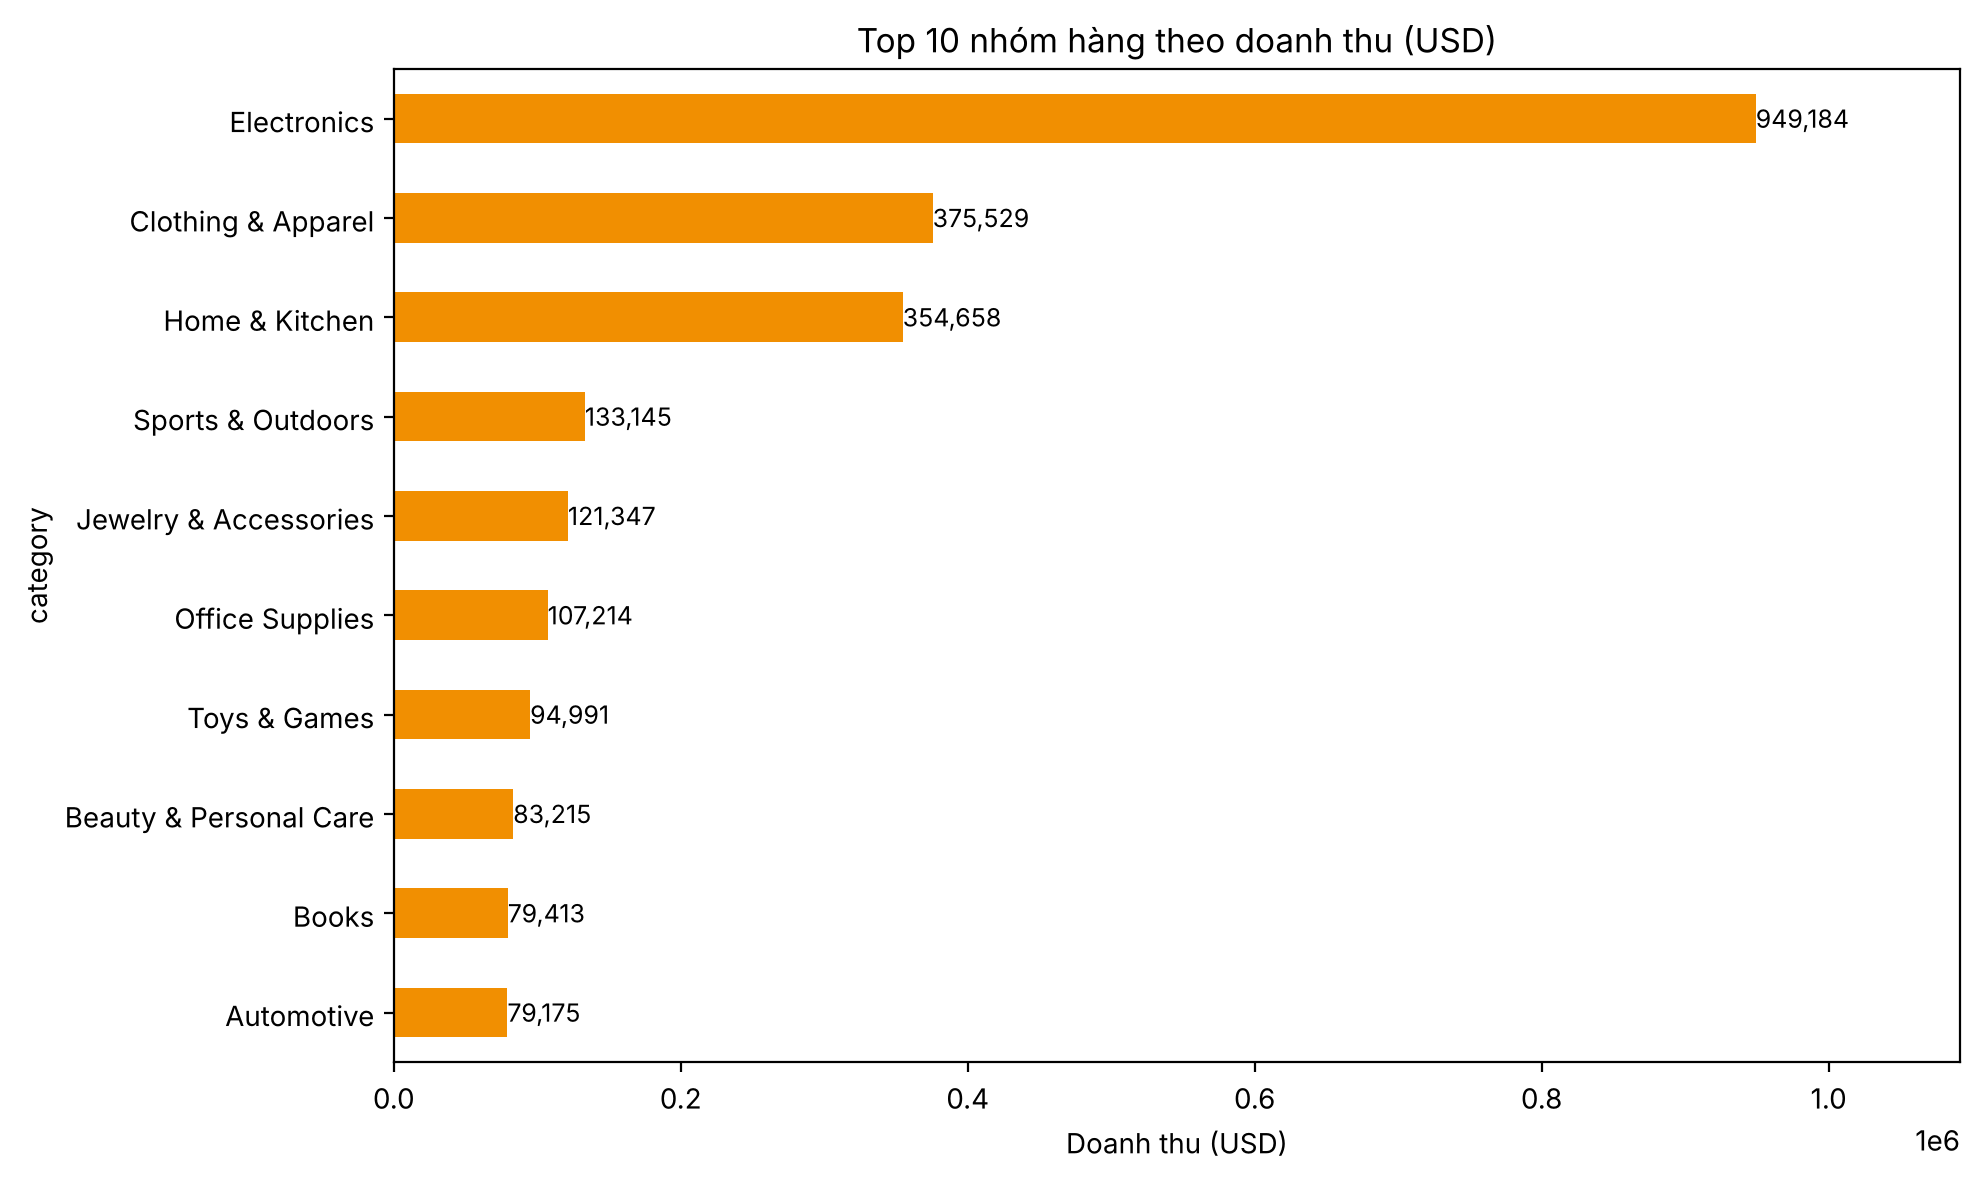

In [6]:
# NOTE: sắp tăng dần để nhóm lớn nhất nằm trên cùng
s = top10_cat['revenue'].sort_values()

ax = s.plot.barh(figsize=(10, 6), color='#F18F01')
ax.set_title('Top 10 nhóm hàng theo doanh thu (USD)')
ax.set_xlabel('Doanh thu (USD)')

for i, value in enumerate(s):           # NOTE: lặp trên s để nhãn khớp từng thanh
    ax.text(value, i, f'{value:,.0f}', va='center', ha='left', fontsize=9)

ax.set_xlim(0, s.max() * 1.15)
plt.tight_layout()
plt.savefig('../exports/archive_static_png/top10_category.png', dpi=150, bbox_inches='tight')
plt.show()

#### 4.3 Nhận xét về nhóm hàng
- **Electronics áp đảo:** **$949,2K = 36,7%** doanh thu, gấp ~2,5 lần nhóm thứ hai (Clothing & Apparel, 14,5%). Electronics vừa **nhiều đơn nhất** (3.716) vừa có **AOV cao nhất nhóm lớn** ($255).
- **Top 3** (Electronics, Clothing, Home & Kitchen) chiếm **65,0%**; **Top 10** chiếm **92,0%**.
- **Books** (1.618 đơn) và **Beauty** (1.401 đơn) có nhiều đơn nhưng AOV chỉ $49–59 nên chỉ đứng thứ 8–9. Ngược lại **Office Supplies** (AOV $169) và **Travel & Luggage** (AOV $177) ít đơn nhưng giá trị mỗi đơn cao.
- Ba nhóm cuối (Food & Grocery, Health & Wellness, Pet Supplies) mỗi nhóm chỉ 1,4–1,9%.

### 5. Kết hợp quốc gia × nhóm hàng (Heatmap)
**Mục tiêu:** trả lời phần "theo quốc gia **và** nhóm hàng": nước nào mạnh ở nhóm nào?
- Dùng bảng **pivot**: hàng = quốc gia, cột = nhóm hàng, giá trị = doanh thu. Chỉ lấy Top 10 × Top 10 cho dễ đọc.
- Chia mỗi hàng cho tổng hàng để ra **% cơ cấu trong từng nước**. Nếu dùng số tuyệt đối, Mỹ sẽ lấn át tất cả và không so sánh được các nước.
- Màu càng đậm = nhóm hàng đó chiếm tỷ trọng càng lớn trong nước.

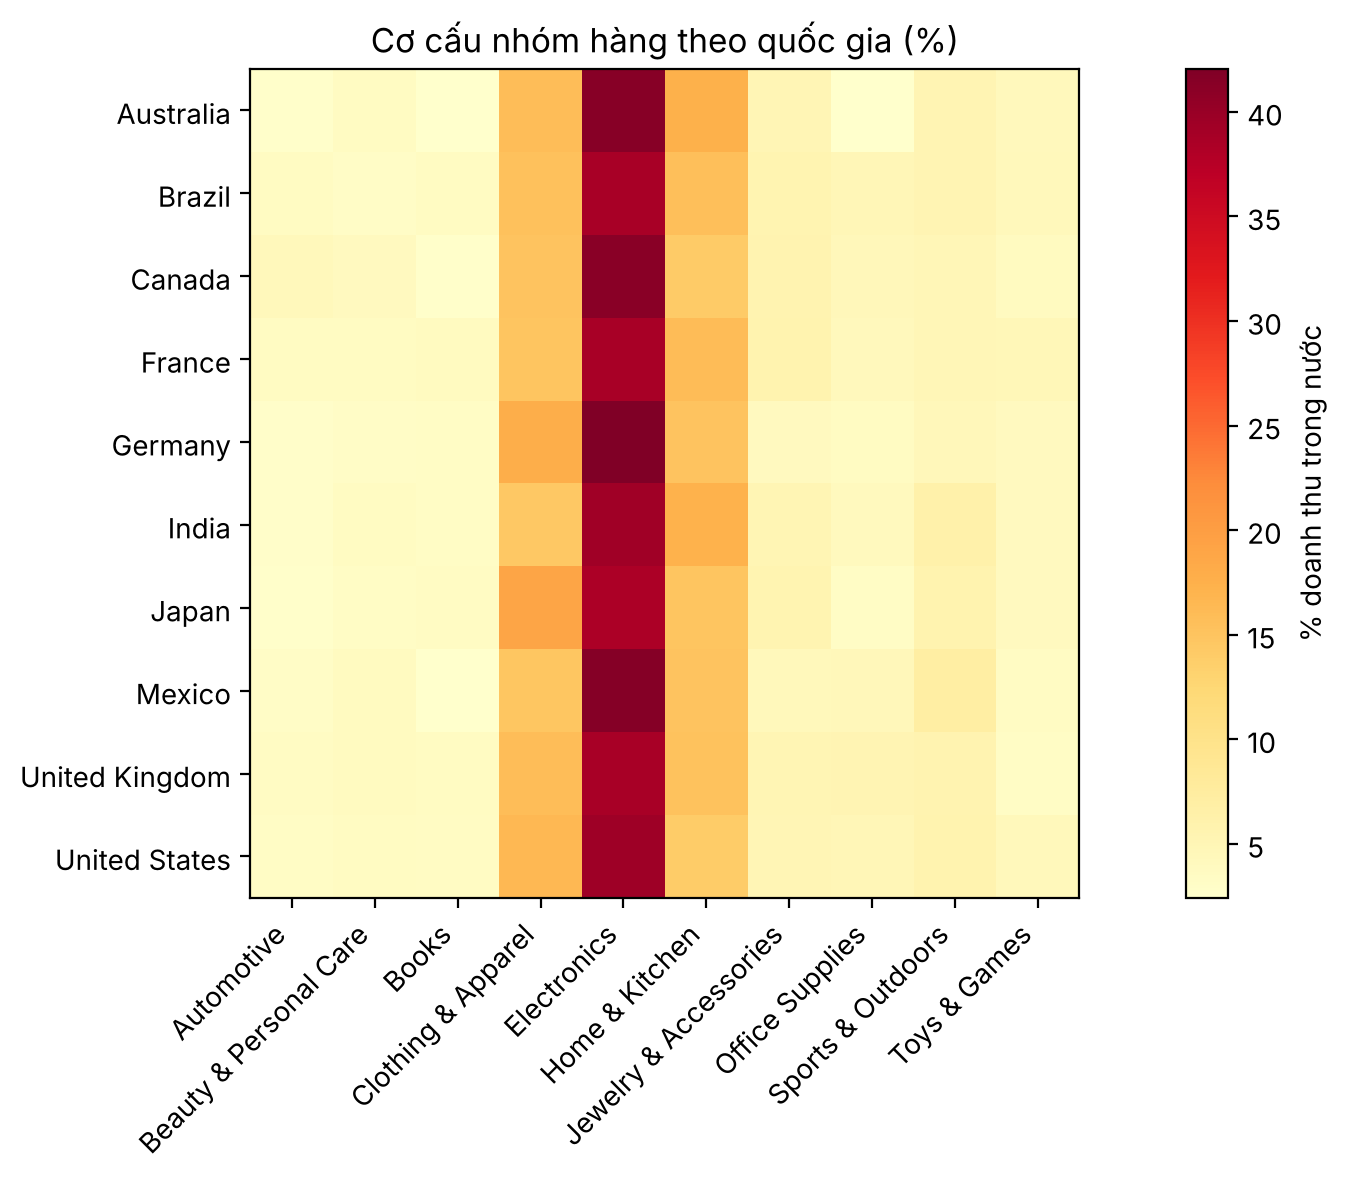

In [7]:
# NOTE: chỉ giữ các nước và nhóm hàng thuộc Top 10 (isin) để bảng gọn, dễ đọc
pv = df[df['country'].isin(top10_country.index) & df['category'].isin(top10_cat.index)] \
    .pivot_table(index='country', columns='category', values='total_amount_usd', aggfunc='sum')

# NOTE: chia mỗi hàng cho tổng hàng (axis=0) -> % cơ cấu nhóm hàng trong TỪNG nước, mỗi hàng cộng = 100%
share = pv.div(pv.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(share, cmap='YlOrRd')
ax.set_xticks(range(share.shape[1]), share.columns, rotation=45, ha='right')
ax.set_yticks(range(share.shape[0]), share.index)
plt.colorbar(im, label='% doanh thu trong nước')
ax.set_title('Cơ cấu nhóm hàng theo quốc gia (%)')
plt.tight_layout()
plt.savefig('../exports/archive_static_png/heatmap_country_category.png', dpi=150, bbox_inches='tight')
plt.show()

#### Nhận xét heatmap
- Cơ cấu nhóm hàng **rất giống nhau giữa các nước**: Electronics luôn chiếm ~38–42%, Clothing ~15–19%, Home & Kitchen ~14–17% → hành vi mua theo nhóm hàng ít phụ thuộc quốc gia.
- Khác biệt nhỏ: Nhật (18,9%) và Đức (17,9%) nghiêng về Clothing; Úc (17,3%) và Ấn Độ (17,2%) nghiêng về Home & Kitchen; Mexico có Sports & Outdoors cao nhất (7,1%).

### 6. Kết luận và đề xuất
**Phát hiện chính**
- Doanh thu tổng $2,585,126.50 từ 20.497 đơn Delivered; tập trung vào **Mỹ (31,1%)** và **Electronics (36,7%)**.
- Doanh thu mỗi nước tỷ lệ với số khách; cơ cấu nhóm hàng giữa các nước tương tự nhau.

**Rủi ro:** phụ thuộc vào một thị trường và một nhóm hàng; nếu một trong hai suy giảm, doanh thu bị ảnh hưởng mạnh.

**Đề xuất**
1. Mở rộng tệp khách ở các thị trường tiềm năng (Anh, Ấn Độ, Đức) vì doanh thu tăng theo số khách.
2. Tăng AOV cho nhóm nhiều đơn nhưng giá thấp (Books, Beauty, Food) bằng combo hoặc bán kèm với Electronics, Home & Kitchen.
3. Đánh giá lại đầu tư cho các nhóm đuôi (Pet, Health, Food, mỗi nhóm < 2%).

**Giới hạn:** chỉ tính đơn Delivered (không gồm 8,1% đơn Returned); quốc gia lấy theo hồ sơ khách hàng.